# OULAD data preparation and preliminary analysis

**Research topic:** Machine Learning Based Prediction of Student Academic Performance in Open University Settings Using Online Engagement  
**Student:** Nyasha Grace Manyonganise  
**Student number:** ST10538027  
**Programme:** Postgraduate Diploma in Data Analytics  
**Module:** RPD8412  

## Purpose of this notebook

This notebook documents the practical preparation of the Open University Learning Analytics Dataset (OULAD). It is written to show what was loaded, why each preparation step was completed, what checks were performed, and what the results mean.

The study uses relational data containing student information, registration records, assessment records, assessment metadata, virtual-learning-environment interactions and activity metadata (Kuzilek, Hlosta and Zdrahal, 2017). The final outcome is converted into a binary target so that the later models can distinguish between successful and adverse outcomes.

The notebook first prepares the data and produces preliminary descriptive outputs. Final model training, hyperparameter tuning and model comparison will be completed after the analytical datasets have been validated.



## 1. Concepts used in this notebook

**Data preparation** means checking and transforming raw data into a consistent form that can be analysed. This includes checking missing values, duplicate records, identification keys and invalid values before creating features or training models (James et al., 2021).

**Feature engineering** means creating useful predictor variables from the original columns. For example, several daily click records can be summarised into total clicks, active days and clicks by activity type. These summaries make the data suitable for a student-level prediction model.

**Data leakage** occurs when information that would not have been available at the prediction time is used to predict the outcome. Final examination information and later outcome-related events are therefore excluded from the early prediction features (James et al., 2021).

**Binary classification** means predicting one of two outcome categories. In this study, Pass and Distinction are coded as 1, while Fail and Withdrawn are coded as 0.

**Hyperparameters** are model settings selected before a model is trained, such as the number of trees in a Random Forest. They are not estimated in this preparation notebook; they will be considered during the later model-tuning stage (James et al., 2021).

## 2. Importing libraries

The libraries below are used for data loading, data manipulation, numerical checks and visualisation. Importing the libraries at the beginning makes the analysis easier to reproduce.

In [1]:
# Loading the libraries needed for data preparation and visualisation
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Applying a consistent visual style to the graphs
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

ERROR! Session/line number was not unique in database. History logging moved to new session 151
Libraries loaded successfully.


## 3. Loading the OULAD files

The raw CSV files are read without changing their original contents. The three large **studentVle** parts are joined vertically, meaning that their rows are placed underneath one another. Each part contains the same header and the same six columns.

In the OUALD folder both original files and split files are in the same folder. The code checks for the split files first. This helps to prevent loading the same files twice.

In [2]:
# Identifying the project folder and the available CSV files
project_folder = Path.cwd()
print("Project folder:", project_folder)
print("Files found:")
print(sorted([file.name for file in project_folder.glob("*.csv")]))

# Loading the five smaller OULAD tables
print("\nLoading assessments.csv...")
assessments = pd.read_csv(project_folder / "assessments.csv", low_memory=False)

print("Loading studentAssessment.csv...")
studentAssessment = pd.read_csv(project_folder / "studentAssessment.csv", low_memory=False)

print("Loading studentInfo.csv...")
studentInfo = pd.read_csv(project_folder / "studentInfo.csv", low_memory=False)

print("Loading studentRegistration.csv...")
studentRegistration = pd.read_csv(project_folder / "studentRegistration.csv", low_memory=False)

print("Loading vle.csv...")
vle = pd.read_csv(project_folder / "vle.csv", low_memory=False)

# Loading the split studentVle files in their filename order
studentVle_parts = sorted(project_folder.glob("studentVle_part_*.csv"))

if studentVle_parts:
    print(f"Loading {len(studentVle_parts)} studentVle split files...")
    studentVle = pd.concat(
        [pd.read_csv(file, low_memory=False) for file in studentVle_parts],
        ignore_index=True
    )
elif (project_folder / "studentVle.csv").exists():
    print("Loading studentVle.csv...")
    studentVle = pd.read_csv(project_folder / "studentVle.csv", low_memory=False)
else:
    raise FileNotFoundError(
        "No studentVle file was found. Place the three split files or the original file in the notebook folder."
    )

# Removing accidental spaces from column names without changing the data values
def clean_column_names(dataframe):
    dataframe = dataframe.copy()
    dataframe.columns = dataframe.columns.astype(str).str.strip()
    return dataframe

assessments = clean_column_names(assessments)
studentAssessment = clean_column_names(studentAssessment)
studentInfo = clean_column_names(studentInfo)
studentRegistration = clean_column_names(studentRegistration)
vle = clean_column_names(vle)
studentVle = clean_column_names(studentVle)

# Keeping the tables together in a dictionary makes repeated checks easier
tables = {
    "assessments": assessments,
    "studentAssessment": studentAssessment,
    "studentInfo": studentInfo,
    "studentRegistration": studentRegistration,
    "vle": vle,
    "studentVle": studentVle,
}

print("\nAll available tables loaded successfully.")
for name, dataframe in tables.items():
    print(f"{name}: {dataframe.shape[0]:,} rows and {dataframe.shape[1]} columns")

Project folder: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD
Files found:
['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'studentVle_part_01.csv', 'studentVle_part_02.csv', 'studentVle_part_03.csv', 'vle.csv']

Loading assessments.csv...
Loading studentAssessment.csv...
Loading studentInfo.csv...
Loading studentRegistration.csv...
Loading vle.csv...
Loading 3 studentVle split files...

All available tables loaded successfully.
assessments: 206 rows and 6 columns
studentAssessment: 173,912 rows and 5 columns
studentInfo: 32,593 rows and 12 columns
studentRegistration: 32,593 rows and 5 columns
vle: 6,364 rows and 6 columns
studentVle: 1,048,575 rows and 6 columns


### Meaning of the loading result

The output above shows the number of rows and columns loaded for each table. The **studentInfo** table is the base table because it contains one student-module-presentation record and the final outcome. The interaction table is larger because one student can have many interaction records across different dates and learning sites.

The output confirms that three split studentVle files were found and loaded. Python combined these files into one dataframe called **studentVle**, which is why the final summary displays one studentVle table rather than three separate tables. The combined studentVle table contains 1,048,575 rows and six columns. This confirms that the split files were successfully reassembled for analysis. The original studentVle.csv file was not loaded because the split files were available and were prioritised by the code.


## 4. Initial structure and data-quality audit

This section checks the structure of every table before any merging takes place. The checks include table size, duplicate rows, missing values and data types. These checks help identify problems early and provide evidence that the preparation process was documented rather than assumed.

In [3]:
# Creating a summary of the structure and basic data quality of each table
audit_rows = []

for name, dataframe in tables.items():
    missing_by_column = dataframe.isna().sum()
    missing_columns = {
        column: int(count)
        for column, count in missing_by_column.items()
        if count > 0
    }

    audit_rows.append({
        "table": name,
        "rows": len(dataframe),
        "columns": len(dataframe.columns),
        "duplicate_rows": int(dataframe.duplicated().sum()),
        "missing_cells": int(dataframe.isna().sum().sum()),
        "columns_with_missing_values": str(missing_columns),
    })

audit_Oulad_df = pd.DataFrame(audit_rows)
display(audit_Oulad_df)

print("\nColumn names by table:")
for name, dataframe in tables.items():
    print(f"{name}: {list(dataframe.columns)}")

,table,rows,columns,duplicate_rows,missing_cells,columns_with_missing_values
0,assessments,206,6,0,11,{'date': 11}
1,studentAssessment,173912,5,0,173,{'score': 173}
2,studentInfo,32593,12,0,1111,{'imd_band': 1111}
3,studentRegistration,32593,5,0,22566,"{'date_registration': 45, 'date_unregistration..."
4,vle,6364,6,0,10486,"{'week_from': 5243, 'week_to': 5243}"
5,studentVle,1048575,6,89529,0,{}



Column names by table:
assessments: ['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']
studentAssessment: ['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']
studentInfo: ['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']
studentRegistration: ['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']
vle: ['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']
studentVle: ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']


### Meaning of the audit result

The audit confirms that all six OULAD tables were loaded with the expected columns. Most tables do not contain exact duplicate rows, but the **studentVle** table contains 89,529 duplicate rows. These duplicates must be investigated before calculating engagement features because counting them could overstate students’ actual activity.

The missing values have different meanings:

- **assessments**: 11 missing dates. These relate to examination records and will not be used as early assessment predictors.
- **studentAssessment**: 173 missing scores. These will not automatically be changed to zero because a missing score does not necessarily mean that the student received zero marks.
- **studentInfo**: 1,111 missing **imd_band** values. This variable will need a documented missing value treatment.
- **studentRegistration**
: most missing values are in **date_unregistration**. This may indicate that students remained registered, so it is not automatically treated as an error.
- **vle**: **week_from** and **week_to** contain missing values. These fields are not required for the current activity-type join, which uses **id_site**.
- **studentVle**: no missing cells were found, but the duplicate-row issue must be checked.

Overall, the data structure is suitable for continuing the preparation process. However, the duplicate **studentVle** records must be investigated before they are used to calculate total clicks and other engagement measures. Data quality checks are completed before merging and modelling to reduce errors in the analytical dataset (James et al., 2021).




### 4.1 Handling missing values



Missing values were examined according to the meaning of each variable. They were not all treated in the same way because a blank value can represent different situations.

Missing assessment dates will not be replaced because these records are not suitable for the early assessment windows. Missing assessment scores will remain missing and will be recorded using a missing value indicator rather than being treated as zero marks.

The missing **imd_band** values will be labelled as **Unknown**. This preserves the student records without guessing their socioeconomic category. Missing registration dates will be retained and flagged for documentation. The missing **week_from** and **week_to** values in the **vle** table will also be retained because these fields are not needed for the current activity type join.

These decisions preserve the meaning of the original data and prevent missing information from being confused with poor performance or zero engagement (Montesinos López, Montesinos López and Crossa, 2022).


In [5]:
# Checking the missing values before applying any treatment
missing_value_summary = pd.DataFrame({
    "table": [
        "assessments",
        "studentAssessment",
        "studentInfo",
        "studentRegistration",
        "vle",
        "studentVle"
    ],
    "missing_values_before_treatment": [
        int(assessments.isna().sum().sum()),
        int(studentAssessment.isna().sum().sum()),
        int(studentInfo.isna().sum().sum()),
        int(studentRegistration.isna().sum().sum()),
        int(vle.isna().sum().sum()),
        int(studentVle.isna().sum().sum())
    ]
})

display(missing_value_summary)

# Checking which types of assessment records have missing dates
print("Assessment types with missing dates:")
display(
    assessments.loc[
        assessments["date"].isna(),
        "assessment_type"
    ].value_counts(dropna=False)
)


,table,missing_values_before_treatment
0,assessments,11
1,studentAssessment,173
2,studentInfo,1111
3,studentRegistration,22566
4,vle,10486
5,studentVle,0


Assessment types with missing dates:


assessment_type
Exam    11
Name: count, dtype: int64

In [6]:
# Creating a missing-score indicator before leaving scores as missing
studentAssessment["score_missing"] = (
    studentAssessment["score"].isna().astype(int)
)

# Creating a missing-value indicator for the socioeconomic variable
studentInfo["imd_band_missing"] = (
    studentInfo["imd_band"].isna().astype(int)
)

# Using Unknown instead of guessing the missing socioeconomic category
studentInfo["imd_band"] = studentInfo["imd_band"].fillna("Unknown")

# Recording missing registration dates without inventing dates
studentRegistration["date_registration_missing"] = (
    studentRegistration["date_registration"].isna().astype(int)
)

studentRegistration["date_unregistration_missing"] = (
    studentRegistration["date_unregistration"].isna().astype(int)
)

# Recording missing VLE activity-period information
vle["week_range_missing"] = (
    vle["week_from"].isna() & vle["week_to"].isna()
).astype(int)

print("Missing-value treatment completed.")


Missing-value treatment completed.


In [7]:
# Confirming which missing values remain after the documented treatment
post_treatment_summary = pd.DataFrame({
    "table": [
        "assessments",
        "studentAssessment",
        "studentInfo",
        "studentRegistration",
        "vle",
        "studentVle"
    ],
    "missing_values_after_treatment": [
        int(assessments.isna().sum().sum()),
        int(studentAssessment.isna().sum().sum()),
        int(studentInfo.isna().sum().sum()),
        int(studentRegistration.isna().sum().sum()),
        int(vle.isna().sum().sum()),
        int(studentVle.isna().sum().sum())
    ]
})

display(post_treatment_summary)

print(
    "Missing assessment scores retained:",
    int(studentAssessment["score"].isna().sum())
)

print(
    "Student records labelled Unknown for imd_band:",
    int((studentInfo["imd_band"] == "Unknown").sum())
)


,table,missing_values_after_treatment
0,assessments,11
1,studentAssessment,173
2,studentInfo,0
3,studentRegistration,22566
4,vle,10486
5,studentVle,0


Missing assessment scores retained: 173
Student records labelled Unknown for imd_band: 1111


In [12]:
# Reloading the original studentInfo table for comparison
studentInfo_before = pd.read_csv(
    project_folder / "studentInfo.csv"
)

studentInfo_before.columns = (
    studentInfo_before.columns.astype(str).str.strip()
)

# Comparing the imd_band values before and after treatment
imd_comparison = pd.DataFrame({
    "value_before_treatment": studentInfo_before["imd_band"],
    "value_after_treatment": studentInfo["imd_band"]
})

# Displaying only the rows that were originally missing
display(
    imd_comparison[
        imd_comparison["value_before_treatment"].isna()
    ].head(10)
)

print(
    "Missing imd_band values before treatment:",
    int(studentInfo_before["imd_band"].isna().sum())
)

print(
    "Missing imd_band values after treatment:",
    int(studentInfo["imd_band"].isna().sum())
)

print(
    "Values changed to Unknown:",
    int((studentInfo["imd_band"] == "Unknown").sum())
)


,value_before_treatment,value_after_treatment
9,NaN,Unknown
17,NaN,Unknown
28,NaN,Unknown
34,NaN,Unknown
65,NaN,Unknown
66,NaN,Unknown
68,NaN,Unknown
88,NaN,Unknown
180,NaN,Unknown
184,NaN,Unknown


Missing imd_band values before treatment: 1111
Missing imd_band values after treatment: 0
Values changed to Unknown: 1111


### Meaning of the missing value treatment result

Before treatment, missing values were found in five tables. After treatment, the 1,111 missing **imd_band** values in **studentInfo** were labelled as **Unknown**, so no student records were removed.

The 173 missing assessment scores were deliberately retained because a missing score does not necessarily mean a mark of zero. The 11 missing assessment dates were also retained for documentation but will be excluded from the early assessment features because they belong to examination records.

The missing registration and VLE timing values were flagged but not replaced with invented values. These values may have a meaningful interpretation and are not required for the current table joins. The **studentVle** table contained no missing values.

Overall, the missing values have now been handled according to the meaning of each variable. Some missing values remain visible because retaining them is safer than changing them without evidence. These decisions will be considered again during feature construction and modelling.


## 5. Identification key and relationship checks

The OULAD tables are relational. Identification keys are used to connect records belonging to the same student, module and presentation. The main student-level key is **id_student**, **code_module** and **code_presentation**. The checks below identify duplicate keys and unmatched relationships before feature construction.

In [13]:
# Defining the keys used to identify records in each table
student_key = ["id_student", "code_module", "code_presentation"]

key_specs = {
    "assessments": ["id_assessment"],
    "studentAssessment": ["id_assessment", "id_student"],
    "studentInfo": student_key,
    "studentRegistration": student_key,
    "vle": ["id_site"],
    "studentVle": ["id_student", "id_site", "date"],
}

# Checking whether the expected keys are repeated
key_audit_rows = []
for name, key_columns in key_specs.items():
    dataframe = tables[name]
    duplicate_key_rows = int(dataframe.duplicated(key_columns, keep=False).sum())
    key_audit_rows.append({
        "table": name,
        "key": ", ".join(key_columns),
        "unique_keys": int(dataframe[key_columns].drop_duplicates().shape[0]),
        "rows_with_repeated_key": duplicate_key_rows,
    })

key_audit_Oulad_df = pd.DataFrame(key_audit_rows)
display(key_audit_Oulad_df)

# Defining a helper function for checking unmatched composite keys
def count_unmatched_keys(left, right, key_columns):
    left_keys = left[key_columns].drop_duplicates()
    right_keys = right[key_columns].drop_duplicates()
    comparison = left_keys.merge(
        right_keys,
        on=key_columns,
        how="left",
        indicator=True
    )
    return int((comparison["_merge"] == "left_only").sum())

# Checking the relationships between the tables
relationship_results = {
    "studentInfo records without registration match": count_unmatched_keys(
        studentInfo, studentRegistration, student_key
    ),
    "studentAssessment rows without assessment match": int(
        (~studentAssessment["id_assessment"].isin(assessments["id_assessment"])).sum()
    ),
    "studentVle rows without VLE site match": int(
        (~studentVle["id_site"].isin(vle["id_site"])).sum()
    ),
}

relationship_Oulad_df = pd.DataFrame(
    relationship_results.items(),
    columns=["relationship_check", "unmatched_records"]
)
display(relationship_Oulad_df)

,table,key,unique_keys,rows_with_repeated_key
0,assessments,id_assessment,206,0
1,studentAssessment,"id_assessment, id_student",173912,0
2,studentInfo,"id_student, code_module, code_presentation",32593,0
3,studentRegistration,"id_student, code_module, code_presentation",32593,0
4,vle,id_site,6364,0
5,studentVle,"id_student, id_site, date",773216,485722


,relationship_check,unmatched_records
0,studentInfo records without registration match,0
1,studentAssessment rows without assessment match,0
2,studentVle rows without VLE site match,0


### Meaning of the key-check result

An identification key is a column, or combination of columns, used to identify a record. A relational check confirms whether records in one table can be correctly linked to the relevant records in another table.

The results show that **id_assessment** uniquely identifies every record in **assessments**. The combined key **id_assessment** and **id_student** also identifies the assessment records without repeated combinations. The combined student key **id_student**, **code_module** and **code_presentation** is unique in both **studentInfo** and **studentRegistration**.

The **id_site** key is unique in the **vle** table, which means that each learning site can be linked to one activity description. The **studentVle** table requires further investigation because repeated student-site-date combinations were found. This does not automatically confirm that the data is incorrect, so the records will be checked before any duplicates are removed.

All three relational checks returned zero unmatched records. This means that every student information record had a registration match, every student assessment record had matching assessment metadata, and every VLE interaction had matching activity metadata.

Overall, the relational links are complete. The only issue requiring further investigation is the repeated key pattern in **studentVle. These checks were completed before feature construction to reduce errors when the tables are merged (James et al., 2021).


### 5.1 Investigating and removing exact duplicate rows

An exact duplicate is a row where all column values are the same as another row. These duplicates can cause some student interactions to be counted more than once.

This step removes only complete duplicate rows. The repeated **id_student**, **id_site**, and **date** combinations identified earlier are not removed here because a repeated key is not necessarily an exact duplicate. Those records are retained for further investigation.

The pandas **duplicated()** and **drop_duplicates()** methods are used to identify and remove exact duplicate rows while keeping the first occurrence (pandas, n.d.).


In [14]:
# Checking for exact duplicate rows

duplicate_mask = studentVle.duplicated(keep="first")
rows_to_remove = duplicate_mask.sum()

print("Starting duplicate investigation...")
print(f"Rows in studentVle: {len(studentVle):,}")
print(f"Exact duplicate rows to remove: {rows_to_remove:,}")

# Displaying a sample of the duplicate rows
display(studentVle.loc[duplicate_mask].head(10))


Starting duplicate investigation...
Rows in studentVle: 1,048,575
Exact duplicate rows to remove: 89,529


,code_module,code_presentation,id_student,id_site,date,sum_click
2,AAA,2013J,28400,546652,-10,1
63,AAA,2013J,45462,546652,-10,1
180,AAA,2013J,77367,546652,-10,4
193,AAA,2013J,94961,546652,-10,2
442,AAA,2013J,248270,546652,-10,4
484,AAA,2013J,258894,546652,-10,3
522,AAA,2013J,246834,547050,-10,1
598,AAA,2013J,281250,546652,-10,3
653,AAA,2013J,300398,546652,-10,4
664,AAA,2013J,302302,546652,-10,2


In [15]:
# Removing exact duplicate rows

studentVle_clean = studentVle.drop_duplicates(
    keep="first",
    ignore_index=True
)

print("Exact duplicate rows removed successfully.")


Exact duplicate rows removed successfully.


In [16]:
# Verifying the duplicate-removal process

verification = pd.DataFrame({
    "check": [
        "Rows before duplicate removal",
        "Exact duplicate rows removed",
        "Rows after duplicate removal",
        "Exact duplicates remaining"
    ],
    "value": [
        len(studentVle),
        rows_to_remove,
        len(studentVle_clean),
        studentVle_clean.duplicated().sum()
    ]
})

display(verification)


,check,value
0,Rows before duplicate removal,1048575
1,Exact duplicate rows removed,89529
2,Rows after duplicate removal,959046
3,Exact duplicates remaining,0


In [17]:
# Checking to see if repeated keys have been retained.

key_columns = ["id_student", "id_site", "date"]

remaining_repeated_keys = studentVle_clean.duplicated(
    subset=key_columns,
    keep=False
).sum()

print(
    f"Rows belonging to repeated student-site-date combinations: "
    f"{remaining_repeated_keys:,}"
)


Rows belonging to repeated student-site-date combinations: 346,408


### Interpretation of removing duplicate records

The verification shows that the exact duplicate rows were removed successfully because zero exact duplicates remain.

However, 346,408 rows still belong to repeated **id_student**, **id_site**, and **date** combinations. This does not automatically mean that these rows are incorrect. They may contain different values in other columns, including the module, presentation, or number of clicks.

Therefore, the repeated key records are retained at this stage and will be investigated before any further deletion is considered.


## 6. Creating the binary target

The original outcome contains four categories. The research design treats Pass and Distinction as successful outcomes and Fail and Withdrawn as adverse outcomes. This creates a binary target for classification while retaining the original **final_result** column for interpretation.

In [18]:
# Creating the binary target used by the later classification models
target_mapping = {
    "Pass": 1,
    "Distinction": 1,
    "Fail": 0,
    "Withdrawn": 0,
}

studentInfo["target"] = studentInfo["final_result"].map(target_mapping)

# Checking whether every outcome was successfully mapped
unmapped_outcomes = studentInfo.loc[studentInfo["target"].isna(), "final_result"].unique()
if len(unmapped_outcomes) > 0:
    raise ValueError(f"Unmapped final outcomes found: {unmapped_outcomes}")

# Summarising the original and binary outcome distributions
outcome_summary = (
    studentInfo["final_result"]
    .value_counts(dropna=False)
    .rename_axis("final_result")
    .reset_index(name="count")
)
outcome_summary["percentage"] = (
    outcome_summary["count"] / outcome_summary["count"].sum() * 100
).round(2)

display(outcome_summary)

print("Binary target values:", sorted(studentInfo["target"].unique().tolist()))

,final_result,count,percentage
0,Pass,12361,37.93
1,Withdrawn,10156,31.16
2,Fail,7052,21.64
3,Distinction,3024,9.28


Binary target values: [0, 1]


### Meaning of the target result

The original four outcome categories are displayed first so that the transformation remains transparent. The new *target* column contains only 0 and 1. A value of 1 represents a successful final outcome, while a value of 0 represents the adverse or at-risk outcome class used for the later prediction task.

## 7. Preparing assessment records

Assessment metadata is joined to student assessment scores using **id_assessment**. Only dated non-examination assessments are eligible for the early prediction windows. Examination information is excluded because it belongs to the final outcome period and could cause data leakage.

The assessment date is used to define when the assessment became available. Missing assessment scores are not automatically converted to zero. Instead, the notebook records the number of missing scores and leaves score averages missing when no valid score is available.

In [19]:
# Converting assessment timing and score columns to numeric values
assessments["date"] = pd.to_numeric(assessments["date"], errors="coerce")
studentAssessment["date_submitted"] = pd.to_numeric(
    studentAssessment["date_submitted"], errors="coerce"
)
studentAssessment["score"] = pd.to_numeric(
    studentAssessment["score"], errors="coerce"
)

# Joining scores to assessment metadata
assessments_merged = studentAssessment.merge(
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("", "_metadata")
)

# Checking that the assessment join was complete
print("Assessment rows without metadata match:", int(
    (assessments_merged["_merge"] == "left_only").sum()
))

# Flagging a non-negative submission date as an observed submission
# This flag is kept separate from the score so missing scores remain visible.
assessments_merged["submitted_flag"] = (
    assessments_merged["date_submitted"].ge(0)
    & assessments_merged["score"].notna()
)

assessment_quality = pd.DataFrame({
    "check": [
        "Missing assessment scores",
        "Assessment records with invalid scores",
        "Assessment metadata rows with missing dates",
        "Examination metadata records",
    ],
    "count": [
        int(studentAssessment["score"].isna().sum()),
        int(((studentAssessment["score"] < 0) | (studentAssessment["score"] > 100)).sum()),
        int(assessments["date"].isna().sum()),
        int((assessments["assessment_type"] == "Exam").sum()),
    ]
})
display(assessment_quality)

Assessment rows without metadata match: 0


,check,count
0,Missing assessment scores,173
1,Assessment records with invalid scores,0
2,Assessment metadata rows with missing dates,11
3,Examination metadata records,24


### Meaning of the assessment result

The results show that all student assessment records have a matching assessment metadata record because no unmatched records were found.There are 173 missing assessment scores. These values will remain missing rather than being changed to zero because a missing score does not necessarily mean that the student received no marks.

No invalid assessment scores were found, which means that all recorded scores fall within the expected scoring range.Eleven assessment metadata records have missing dates. The results also show that 24 assessment metadata records are examinations. The missing dates will be retained because there is not enough information to determine the correct dates without creating unsupported values.

The assessment data is suitable for further preparation. The missing scores and dates have been identified and will be considered during feature construction.


## 8. Defining the prediction windows

The study compares early information at weeks 2, 4 and 6. In this notebook, week N is defined as cumulative information available up to day 7 multiplied by N. Therefore, the cutoffs are day 14, day 28 and day 42. Making the cutoffs explicit avoids accidentally including later records because of rounding.

This approach creates three separate datasets so that the predictive information available at each time point can be compared fairly (Adnan et al., 2021).

In [20]:
# Defining explicit cumulative cutoffs for the three prediction windows
WINDOW_CUTOFFS = {
    2: 14,
    4: 28,
    6: 42,
}

print("Prediction windows:")
for window, cutoff in WINDOW_CUTOFFS.items():
    print(f"Week {window}: records dated on or before day {cutoff}")

Prediction windows:
Week 2: records dated on or before day 14
Week 4: records dated on or before day 28
Week 6: records dated on or before day 42


## 9. Creating assessment features for each window

This section converts multiple assessment rows into one student-level record. The resulting features include the number of assessment records, the number of scored assessments, the number submitted, the submission rate, the mean score and separate mean TMA and CMA scores.

The aggregation step is a form of feature engineering. It is needed because the final model will have one row per student-module-presentation, while the raw assessment table can have many rows for one student.

In [ ]:
# Creating assessment features for one prediction window
def build_assessment_features(cutoff_day): # This function is created so that it builds features only using data before the date (cuttoff_day) 
    # Keep only dated, non-examination assessments available by the cutoff
    eligible = assessments_merged.loc[
        assessments_merged["date"].notna() # This means we are keeping rows were the given date isnt empty.
        & (assessments_merged["date"] <= cutoff_day) # So if cut offs is 30 we ignore day 31 assessments
        & (assessments_merged["assessment_type"] != "Exam") # we only need noraml assignmnents / TMA assessments and not exams 
    ].copy()

    # Count assessment records and observed scores for each student
    grouped = eligible.groupby(student_key, as_index=False).agg(
        #Now for each student, here we summarise all eligible assessments into one row
        assessment_record_count=("id_assessment", "count"),
        scored_assessment_count=("score", "count"),
        submitted_assessment_count=("submitted_flag", "sum"), # This looks at how many did a student submit ...The flag is 1 if submitted and 0 if not. 
        assessment_score_mean=("score", "mean"), # This is the average score for that student up to cutoff
        assessment_score_missing_count=("score", lambda values: values.isna().sum()), # checking how many scores are still missing 
    )

    # Calculating the submission rate only for the records in the selected window
    # This is just the math. For example, if 5 assessments were due and the student submitted 4, the rate is 0.8 or 80%. This tells us how reliable the student is. And 
    # that they are actually doing their work.   
    grouped["assessment_submission_rate"] = (
        grouped["submitted_assessment_count"]
        / grouped["assessment_record_count"]
    )

    # Calculating separate averages for tutor-marked and computer-marked assessments
    type_scores = (
        eligible.loc[eligible["score"].notna()]
        .pivot_table(
            index=student_key,
            columns="assessment_type",
            values="score",
            aggfunc="mean"
        )
        .reset_index()
    )

    type_scores = type_scores.rename(columns={
        "TMA": "avg_TMA_score",
        "CMA": "avg_CMA_score",
    })

    # Combining the general and assessment-type features
    features = grouped.merge(type_scores, on=student_key, how="left")
    return features

assessment_features_by_window = {}
for window, cutoff in WINDOW_CUTOFFS.items():
    print(f"Creating assessment features for week {window}...")
    assessment_features_by_window[window] = build_assessment_features(cutoff)
    print("Rows created:", len(assessment_features_by_window[window]))

display(assessment_features_by_window[2].head())

Creating assessment features for week 2...
Rows created: 1189
Creating assessment features for week 4...
Rows created: 21099
Creating assessment features for week 6...
Rows created: 23530


,id_student,code_module,code_presentation,assessment_record_count,scored_assessment_count,submitted_assessment_count,assessment_score_mean,assessment_score_missing_count,assessment_submission_rate,avg_TMA_score
0,27891,BBB,2014B,1,1,0,73.0,0,0.0,73.0
1,38941,BBB,2014B,1,1,1,77.0,0,1.0,77.0
2,50069,BBB,2014B,1,1,1,78.0,0,1.0,78.0
3,52426,BBB,2014B,1,1,1,46.0,0,1.0,46.0
4,55968,BBB,2014B,1,1,1,62.0,0,1.0,62.0


### Results

This table was created by summarising the original student assessment records. Instead of keeping several assessment rows for the same student and course, the assessment information is converted into summary features for each student, module, and presentation.

The features describe the number of assessments available, the number of assessments with scores, the average score, missing scores, and submission behaviour. These features provide a consistent format that can be used by the machine-learning models.

The features are created separately for weeks 2, 4, and 6. This allows the study to test whether prediction performance improves when more assessment information becomes available. The assessment features will later be combined with VLE activity features and the binary target variable.

For week 2, 1,189 feature rows were created. For week 4, 21,099 rows were created, and for week 6, 23,530 rows were created. The increase occurs because more assessment information is available later in the course.


## 10. Preparing VLE interaction records

The **studentVle** table records interaction counts, while the **vle** table identifies the activity type associated with each learning site. The two tables are joined using **id_site**.

The VLE records are then aggregated into student level engagement features, including total clicks, active days, unique learning sites and clicks by activity type. This notebook therefore retains records on or before each cutoff and reports the number of negative date records so that this decision can be confirmed before final modelling.

In [22]:
# Using the cleaned studentVle table for engagement feature construction
# NOTE: We cleaned the studentVLE 
studentVle = studentVle_clean.copy()

print(f"Rows used for engagement features: {len(studentVle):,}")


Rows used for engagement features: 959,046


In [24]:
# Converting VLE timing and click columns to numeric values
studentVle["date"] = pd.to_numeric(studentVle["date"], errors="coerce")
studentVle["sum_click"] = pd.to_numeric(studentVle["sum_click"], errors="coerce")
vle["week_from"] = pd.to_numeric(vle["week_from"], errors="coerce")
vle["week_to"] = pd.to_numeric(vle["week_to"], errors="coerce")

# Linking each interaction to its learning activity type
studentVle_merged = studentVle.merge(
    vle[["id_site", "activity_type"]],
    on="id_site",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("VLE rows without activity metadata match:", int(
    (studentVle_merged["_merge"] == "left_only").sum()
))
print("Pre-course VLE records:", int((studentVle_merged["date"] < 0).sum()))
print("Invalid negative click records:", int((studentVle_merged["sum_click"] < 0).sum()))

# Creating engagement features for one prediction window
def build_engagement_features(cutoff_day):
    # Retain all records available on or before the selected cutoff
    eligible = studentVle_merged.loc[
        studentVle_merged["date"].notna()
        & (studentVle_merged["date"] <= cutoff_day)
    ].copy()

    # Summarising the interaction behaviour for each student-module-presentation
    grouped = eligible.groupby(student_key, as_index=False).agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique"),
        unique_learning_sites=("id_site", "nunique"),
        interaction_records=("id_site", "count"),
    )

    # Calculating the total clicks for each activity type
    activity_features = (
        eligible.pivot_table(
            index=student_key,
            columns="activity_type",
            values="sum_click",
            aggfunc="sum",
            fill_value=0
        )
        .reset_index()
    )

    # Giving activity features clear names for the final dataset
    activity_features.columns = [
        column if column in student_key else f"clicks_activity_{column}"
        for column in activity_features.columns
    ]

    features = grouped.merge(activity_features, on=student_key, how="left")
    return features

engagement_features_by_window = {}
for window, cutoff in WINDOW_CUTOFFS.items():
    print(f"Creating engagement features for week {window}...")
    engagement_features_by_window[window] = build_engagement_features(cutoff)
    print("Rows created:", len(engagement_features_by_window[window]))

display(engagement_features_by_window[2].head())

VLE rows without activity metadata match: 0
Pre-course VLE records: 62872
Invalid negative click records: 0
Creating engagement features for week 2...
Rows created: 3927
Creating engagement features for week 4...
Rows created: 4066
Creating engagement features for week 6...
Rows created: 4099


,id_student,code_module,code_presentation,total_clicks,active_days,unique_learning_sites,interaction_records,clicks_activity_dataplus,clicks_activity_forumng,clicks_activity_glossary,clicks_activity_homepage,clicks_activity_oucollaborate,clicks_activity_oucontent,clicks_activity_ouelluminate,clicks_activity_quiz,clicks_activity_resource,clicks_activity_sharedsubpage,clicks_activity_subpage,clicks_activity_url
0,6516,AAA,2014J,538,20,26,109,0,146,0,109,0,207,0,0,15,0,34,27
1,11391,AAA,2013J,300,6,21,44,0,19,0,31,0,221,0,0,8,0,20,1
2,23629,BBB,2013B,40,4,7,15,0,23,0,10,0,0,0,0,2,0,5,0
3,23798,BBB,2013J,89,6,14,39,0,36,0,17,1,19,0,0,1,0,9,6
4,24734,AAA,2014J,50,5,15,24,0,5,0,22,0,20,0,0,1,0,2,0


### Results 

The VLE interaction data was successfully linked to the activity metadata because no unmatched activity records were found.

The data contains 62,872 pre-course VLE records. These records have negative date values because the OULAD date variable measures the number of days relative to the official course start date. Negative values therefore represent activity that occurred before the course started, rather than automatically indicating data errors (ouladFormat, n.d.). These records were retained because they may represent early student engagement.

No invalid negative click values were found, confirming that the recorded click counts are valid.

The VLE data was converted into engagement features for weeks 2, 4, and 6. These features include total clicks, active days, unique learning sites, interaction records, and clicks by activity type. They summarise each student's engagement before each prediction point.

For example, in the week 2 feature table, student 6516 was studying module AAA during presentation 2014J. The student recorded 538 total clicks across 20 active days, accessed 26 unique learning sites, and had 109 interaction records. The activity-specific click columns show how the total clicks were distributed across different activity types, such as forum activities, OU content, the homepage, resources, subpages, and URLs.

This example shows that the table is not simply listing individual VLE log records. It is summarising the student's activity into measurable features that can be used by the machine-learning models. The assessment features and the binary target will later be combined with these engagement features.


## 11. Constructing the three analytical datasets

The base dataset is created from **studentInfo**. Registration information is checked and the registration date is retained as a possible predictor. **date_unregistration** is excluded because it may reveal a later withdrawal event and could leak information about the final outcome.

The engagement and assessment features are then merged into the base table. The expected result is one row per student-module-presentation for each prediction window.

In [25]:
# Creating the base student level table
base_columns = student_key + [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability",
    "final_result",
    "target",
]

base_dataset = studentInfo[base_columns].copy()

# Adding registration timing while excluding possible outcome-related unregistration timing
registration_features = studentRegistration[student_key + ["date_registration"]].copy()
base_dataset = base_dataset.merge(
    registration_features,
    on=student_key,
    how="left",
    validate="one_to_one"
)

# Creating the final analytical dataset for one prediction window
def build_window_dataset(window):
    engagement = engagement_features_by_window[window]
    assessment = assessment_features_by_window[window]

    dataset = base_dataset.merge(
        engagement,
        on=student_key,
        how="left",
        validate="one_to_one"
    ).merge(
        assessment,
        on=student_key,
        how="left",
        validate="one_to_one"
    )

    # Filling only engagement count features with zero means no recorded activity
    engagement_feature_columns = [
        column for column in engagement.columns
        if column not in student_key
    ]
    dataset[engagement_feature_columns] = dataset[engagement_feature_columns].fillna(0)

    # Filling assessment counts with zero means no assessment record was available
    assessment_count_columns = [
        "assessment_record_count",
        "scored_assessment_count",
        "submitted_assessment_count",
        "assessment_score_missing_count",
        "assessment_submission_rate",
    ]
    for column in assessment_count_columns:
        if column in dataset.columns:
            dataset[column] = dataset[column].fillna(0)

    # Keeping score averages missing when no valid score exists
    score_columns = [
        "assessment_score_mean",
        "avg_TMA_score",
        "avg_CMA_score",
    ]
    for column in score_columns:
        if column in dataset.columns:
            dataset[f"{column}_missing"] = dataset[column].isna().astype(int)

    dataset["prediction_window_week"] = window
    return dataset

analytical_datasets = {}
for window in WINDOW_CUTOFFS:
    print(f"Constructing analytical dataset for week {window}...")
    analytical_datasets[window] = build_window_dataset(window)
    dataset = analytical_datasets[window]
    print("Rows:", len(dataset), "Columns:", len(dataset.columns))
    print("Duplicate student-level keys:", int(dataset.duplicated(student_key).sum()))

display(analytical_datasets[2].head())

Constructing analytical dataset for week 2...
Rows: 32593 Columns: 40
Duplicate student-level keys: 0
Constructing analytical dataset for week 4...
Rows: 32593 Columns: 42
Duplicate student-level keys: 0
Constructing analytical dataset for week 6...
Rows: 32593 Columns: 42
Duplicate student-level keys: 0


,id_student,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,target,date_registration,total_clicks,active_days,unique_learning_sites,interaction_records,clicks_activity_dataplus,clicks_activity_forumng,clicks_activity_glossary,clicks_activity_homepage,clicks_activity_oucollaborate,clicks_activity_oucontent,clicks_activity_ouelluminate,clicks_activity_quiz,clicks_activity_resource,clicks_activity_sharedsubpage,clicks_activity_subpage,clicks_activity_url,assessment_record_count,scored_assessment_count,submitted_assessment_count,assessment_score_mean,assessment_score_missing_count,assessment_submission_rate,avg_TMA_score,assessment_score_mean_missing,avg_TMA_score_missing,prediction_window_week
0,11391,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,1,-159.0,300.0,6.0,21.0,44.0,0.0,19.0,0.0,31.0,0.0,221.0,0.0,0.0,8.0,0.0,20.0,1.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,1,1,2
1,28400,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1,-53.0,447.0,14.0,29.0,119.0,0.0,165.0,0.0,99.0,0.0,116.0,0.0,0.0,5.0,0.0,43.0,19.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,1,1,2
2,30268,AAA,2013J,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,0,-92.0,260.0,12.0,22.0,72.0,0.0,105.0,0.0,59.0,0.0,66.0,0.0,0.0,4.0,0.0,22.0,4.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,1,1,2
3,31604,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,1,-52.0,336.0,13.0,24.0,87.0,0.0,84.0,1.0,65.0,0.0,125.0,0.0,0.0,10.0,0.0,38.0,13.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,1,1,2
4,32885,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1,-176.0,465.0,17.0,30.0,108.0,0.0,117.0,2.0,81.0,0.0,235.0,0.0,0.0,7.0,0.0,20.0,3.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,1,1,2


### Results

The analytical datasets for weeks 2, 4, and 6 were created by combining student information, VLE engagement features, and assessment features. Each row represents one student taking one module during one presentation.

The datasets contain 32,593 rows. No duplicate student-module-presentation keys were found, confirming that each student-course record appears only once in the analytical dataset.

The week 2 dataset contains 40 columns, while the week 4 and week 6 datasets contain 42 columns. These columns include student information, registration information, VLE engagement measures, and assessment measures available up to each prediction week.

The **final_result** and **target** columns show the actual outcome for each student. The **target** column converts the outcome into a numerical value, where a successful outcome is coded as 1 and an unsuccessful outcome is coded as 0. For example, a student with **final_result** equal to **Pass** has a **target** value of 1, while a student with **final_result** equal to **Withdrawn** has a **target** value of 0.

The target column is included at this stage because it will be used later to train and evaluate the machine-learning models. It is not a model prediction or a final performance result. During modelling, **target** and **final_result** will be excluded from the predictor variables so that the models do not receive the answer in advance.

The negative registration dates are retained because dates in the OULAD dataset are measured relative to the course start date. A negative value indicates that the student registered before the official course start.

## 12. Comparing the three preliminary datasets

This summary checks the size, target distribution and early engagement level of each dataset. It provides an initial descriptive view before model training and helps identify whether the three windows were constructed consistently.

In [26]:
# Summarising the three analytical datasets
window_summary_rows = []
for window, dataset in analytical_datasets.items():
    window_summary_rows.append({
        "window": f"Week {window}",
        "rows": len(dataset),
        "columns": len(dataset.columns),
        "successful_outcome_percent": round(dataset["target"].mean() * 100, 2),
        "adverse_outcome_percent": round((1 - dataset["target"].mean()) * 100, 2),
        "mean_total_clicks": round(dataset["total_clicks"].mean(), 2),
        "students_with_clicks": int((dataset["total_clicks"] > 0).sum()),
        "missing_mean_assessment_scores": int(dataset["assessment_score_mean"].isna().sum()),
    })

window_summary = pd.DataFrame(window_summary_rows)
display(window_summary)

,window,rows,columns,successful_outcome_percent,adverse_outcome_percent,mean_total_clicks,students_with_clicks,missing_mean_assessment_scores
0,Week 2,32593,40,47.2,52.8,21.03,3927,31405
1,Week 4,32593,42,47.2,52.8,32.36,4066,11521
2,Week 6,32593,42,47.2,52.8,41.32,4099,9094


### Purpose of comparing the analytical datasets

The analytical dataset was created three times, using information available at Week 2, Week 4, and Week 6. The summary table checks whether the datasets behave logically as the prediction window moves later in the course.

The number of rows remained constant at 32,593 for all three windows. This confirms that students were not being lost during the feature construction or merging process.

The successful outcome percentage remained 47.2%, while the adverse outcome percentage remained 52.8%. This is expected because the target represents the student's final course outcome, which does not change between prediction windows. These percentages describe the target distribution and are not model performance results.

Mean total clicks increased from 21.03 in Week 2 to 32.36 in Week 4 and 41.32 in Week 6. This shows that students had more time to interact with the VLE as the course progressed.

The number of students with recorded clicks increased from 3,927 in Week 2 to 4,066 in Week 4 and 4,099 in Week 6. This indicates that more engagement information became available in the later windows.

Missing mean assessment scores decreased from 31,405 in Week 2 to 11,521 in Week 4 and 9,094 in Week 6. This is expected because fewer assessments were available at the beginning of the course, while more assessment scores became available later.

The Week 2 dataset contains 40 columns, while the Week 4 and Week 6 datasets contain 42 columns. This indicates that additional features were available in the later prediction windows.

Overall, the results behave logically. The number of student records and the final target distribution remain stable, while engagement increases and missing assessment information decreases as the prediction window moves later.


## 13. Preliminary visualisations

Graphs are used here to make the initial patterns easier to inspect. The first graph shows the binary outcome distribution. The second graph compares total clicks between the two outcome groups using a logarithmic transformation so that very large click counts do not hide the lower values.

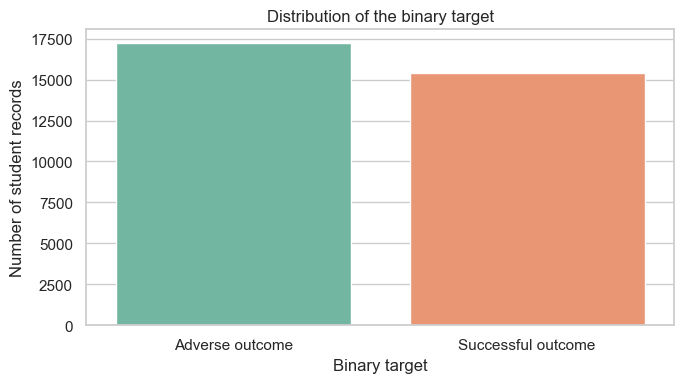

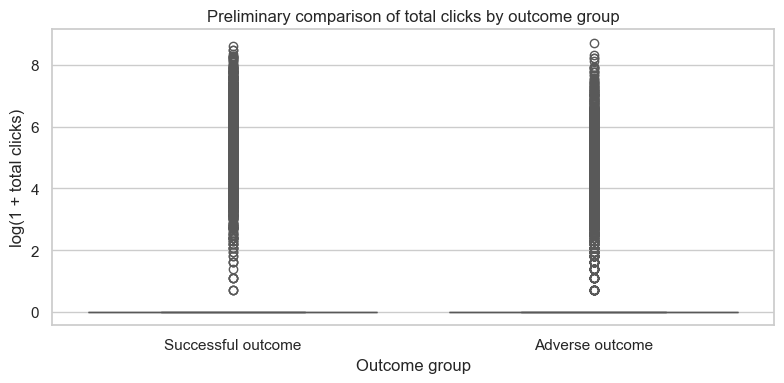

In [27]:
# Plotting the target distribution for the week-six dataset
week6 = analytical_datasets[6]

plt.figure(figsize=(7, 4))
sns.countplot(data=week6, x="target", hue="target", palette="Set2", legend=False)
plt.xticks([0, 1], ["Adverse outcome", "Successful outcome"])
plt.xlabel("Binary target")
plt.ylabel("Number of student records")
plt.title("Distribution of the binary target")
plt.tight_layout()
plt.show()

# Plotting total clicks by target using log1p to include zero-click records
plot_data = week6[["target", "total_clicks"]].copy()
plot_data["log_total_clicks"] = np.log1p(plot_data["total_clicks"])
plot_data["outcome_group"] = plot_data["target"].map({
    0: "Adverse outcome",
    1: "Successful outcome",
})

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=plot_data,
    x="outcome_group",
    y="log_total_clicks",
    hue="outcome_group",
    palette="Set2",
    legend=False
)
plt.xlabel("Outcome group")
plt.ylabel("log(1 + total clicks)")
plt.title("Preliminary comparison of total clicks by outcome group")
plt.tight_layout()
plt.show()

### Interpretation of the preliminary visual checks

The first graph shows the distribution of the binary target. The adverse-outcome group is slightly larger than the successful-outcome group. This agrees with the summary results, which showed 52.8% adverse outcomes and 47.2% successful outcomes. The difference is relatively small, so the dataset does not appear to have a severe imbalance between the two target classes.

The second graph compares total VLE clicks between successful and adverse outcome groups. The total clicks variable was transformed using **log(1 + total_clicks)**. This transformation reduces the effect of extremely large click values and makes the distribution easier to display (NumPy, n.d.).

Most observations are concentrated near the lower end of the graph, while the circles extending upwards represent students with much higher click totals. Both outcome groups contain high click observations and have a similar overall spread. Therefore, the graph does not show a clear separation between successful and adverse outcomes based on total clicks alone.

These graphs are preliminary descriptive checks, not final model results. The machine learning models will later assess whether total clicks, activity-specific clicks, assessment features, and student information can be combined to improve prediction of the final outcome.


## 14. Saving the prepared outputs

The preparation outputs are saved as separate CSV files so that the work can be inspected and reproduced without modifying the raw source files. A preparation log is also created to record the main decisions made in this notebook.

In [28]:
# Creating a separate output folder so that raw files remain unchanged

output_folder = project_folder / "oulad_outputs"
output_folder.mkdir(parents=True, exist_ok=True)

# Saving each analytical dataset
for window, dataset in analytical_datasets.items():
    output_path = output_folder / f"oulad_analytical_week_{window}.csv"
    dataset.to_csv(output_path, index=False)
    print("Saved:", output_path.name)

# Saving the audit tables
audit_Oulad_df.to_csv(
    output_folder / "table_quality_audit.csv",
    index=False
)

key_audit_Oulad_df.to_csv(
    output_folder / "key_audit.csv",
    index=False
)

relationship_Oulad_df.to_csv(
    output_folder / "relationship_audit.csv",
    index=False
)

window_summary.to_csv(
    output_folder / "window_summary.csv",
    index=False
)

# Creating a simple preparation log for the project records

log_text = """# OULAD data preparation log

## Date

The notebook was prepared during August 2026.

## Files loaded

The analysis used the assessments, studentAssessment, studentInfo, studentRegistration, vle and studentVle tables. The studentVle table was read from split CSV files and recombined vertically.

## Preparation decisions

1. Raw source files were read without overwriting them.
2. Column names were stripped of accidental surrounding spaces.
3. Duplicate rows, duplicate keys, missing values and unmatched relationships were checked before merging.
4. Pass and Distinction were coded as 1. Fail and Withdrawn were coded as 0.
5. Examination records were excluded from early assessment predictors.
6. Assessment score missingness was retained and represented with missingness indicators.
7. Engagement count features were filled with zero after merging because no interaction record represents no recorded activity for that feature.
8. Separate cumulative prediction windows were created at weeks 2, 4 and 6 using day cutoffs of 14, 28 and 42.
9. Negative-date VLE records were reported and retained because they represent activity before the official course start date.
10. date_unregistration was excluded from predictors because it may reveal a later withdrawal event.

## Preliminary status

The datasets and audit tables were created for preliminary analysis. Model training, hyperparameter tuning, SMOTE and final evaluation metrics are not completed in this preparation stage.
"""

# Saving the preparation log
log_path = output_folder / "data_preparation_log.md"
log_path.write_text(log_text, encoding="utf-8")

print("Saved audit tables and data preparation log in:", output_folder)


Saved: oulad_analytical_week_2.csv
Saved: oulad_analytical_week_4.csv
Saved: oulad_analytical_week_6.csv
Saved audit tables and data preparation log in: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD\oulad_outputs


## 15. Current stopping point

This notebook completes the documented data-loading, data-quality, feature-construction and preliminary-analysis stage. It does not yet claim that any algorithm is the best model.

The next modelling stage should use the three validated analytical datasets to train Logistic Regression, Random Forest and XGBoost. It should then compare recall, precision, F1 score, accuracy, ROC-AUC and confusion matrices, with particular attention to identifying adverse-outcome students. These later steps should be documented separately from the preparation checks.

## References

Adnan, M., Habib, A., Ashraf, J., Mussadiq, S., Raza, A.A., Abid, M., Bashir, M. and Khan, S.U. 2021. ‘Predicting at-risk students at different percentages of course length for early intervention using machine learning models’. *IEEE Access*, 9, pp. 7519–7539. [Online]. Available at: https://doi.org/10.1109/ACCESS.2021.3049446 [Accessed 26 August 2026].

Bergdahl, N., Bond, M., Sjöberg, J., Dougherty, M. and Oxley, E. 2024. ‘Unpacking student engagement in higher education learning analytics: A systematic review’. *International Journal of Educational Technology in Higher Education*, 21, article 63. [Online]. Available at: https://doi.org/10.1186/s41239-024-00493-y [Accessed 26 August 2026].

James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J. 2023. *An introduction to statistical learning: With applications in Python*. 1st ed. Cham: Springer. [Online]. Available at: https://doi.org/10.1007/978-3-031-38747-0 [Accessed 26 August 2026].

Kužílek, J., Hlosta, M. and Zdráhal, Z. 2017. ‘Open University Learning Analytics dataset’. *Scientific Data*, 4(1), article 170171. [Online]. Available at: https://doi.org/10.1038/sdata.2017.171 [Accessed 26 August 2026].

NumPy (n.d.) *numpy.log1p*. [Online]. Available at: https://numpy.org/doc/stable/reference/generated/numpy.log1p.html [Accessed 26 August 2026].

ouladFormat (n.d.) *ouladFormat: Loads and formats the Open University Learning Analytics Dataset for Data Analysis*. [Online]. Available at: https://doi.org/10.32614/CRAN.package.ouladformat [Accessed 26 August 2026].

pandas (n.d.) *DataFrame.drop_duplicates*. [Online]. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html [Accessed 26 August 2026].
